In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import sys
sys.path.append("/home/dev/pose/pose")

import yaml

WORK_DIR = "/home/dev/pose"

In [3]:
%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

In [4]:
config_fname = "/home/dev/pose/configs/resnet50_simcc-tr.yaml"

with open(config_fname) as config_fin:
    cfg = yaml.load(config_fin, Loader=yaml.Loader)

In [5]:
from data.dataset import CocoDataset

In [6]:
connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [7]:
dataset = CocoDataset(os.path.join(WORK_DIR, cfg['train_data']['anno_fname']),
                      os.path.join(WORK_DIR, cfg['train_data']['image_dir']))

2024-12-19 11:21:37.877 | INFO     | data.dataset:init_coco_info:78 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankle')])
2024-12-19 11:21:40.054 | INFO     | data.dataset:__init__:26 - Annotation fname: /home/dev/pose/data/coco/annotations/person_keypoints_train2017.json
2024-12-19 11:21:40.127 | INFO     | data.dataset:__init__:38 - Num images: 118,287
2024-12-19 11:21:40.128 | INFO     | data.dataset:__init__:41 - Num raw annotations: 262,465
2024-12-19 11:21:43.229 | INFO     | data.dataset:__init__:64 - skip crowd: 5,212
2024-12-19 11:21:43.230 | INFO     | data.dataset:__init__:65 - skip not human: 0
2024-12-19 11:21:43.230 | INFO     | data.dataset:__init__:66 - skip insufficient keypoints: 107,440
2024-12-19 11:21:43.230 | INFO     | data.dataset

In [8]:
sample = dataset.get_sample(0)
image_meta = dataset.get_image_meta(sample['image_id'])
image_path = image_meta['file_name']

In [9]:
sample.keys()

dict_keys(['keypoints', 'bbox', 'image_id', 'id'])

In [10]:
image_meta.keys()

dict_keys(['file_name', 'height', 'width'])

In [11]:
def label_affine(kp, angle, bbox_center):
    theta = -1 * math.pi * angle / 180
    M = [[math.cos(theta), -1 * math.sin(theta)],
         [math.sin(theta), math.cos(theta)]]
    M = torch.tensor(M)

    return torch.matmul((kp[:,:2] - bbox_center).float(), M).int() + bbox_center

In [115]:
import math


def adjust_bbox(kp, vis, height, width):
    _kp = kp[vis > 0]
    x_max = _kp[:,0].max()
    x_min = _kp[:,0].min()
    y_max = _kp[:,1].max()
    y_min = _kp[:,1].min()
    bbox_width = x_max - x_min
    bbox_height = y_max - y_min
    xpad = math.ceil(bbox_width * 0.1)
    ypad = math.ceil(bbox_height * 0.1)
    bbox = [int(x_min-xpad), int(y_min-ypad), int(x_max+xpad), int(y_max+ypad)]
    print(f"new bbox(before padding): {bbox}")
    bbox = torch.tensor([[max(x_min-xpad, 0),
                          max(y_min-ypad, 0),
                          min(x_max+xpad, width),
                          min(y_max+ypad, height)]])
    return bbox

In [182]:
def test():
    sample_idx = random.randint(0, len(dataset)-1)
    print(f"Sample index: {sample_idx}")
    sample = dataset.get_sample(sample_idx)
    image_meta = dataset.get_image_meta(sample['image_id'])
    image_path = image_meta['file_name']
    print(f"Image path: {image_path}")
    height = image_meta['height']
    width = image_meta['width']
    print(f"H:{height}, W:{width}")

    bbox = sample['bbox']
    bbox_4p = torch.tensor([[bbox[0], bbox[1], bbox[0]+bbox[2], bbox[1]+bbox[3]]])
    print(f"bbox: {bbox}")

    kp = sample['keypoints']
    kp_formatted = kp[:,:2].reshape(1,17,2)
    visibility = kp[:,2].reshape(1,17)
    print(f"Keypoints: {kp}")

    img = read_image(image_path)
    img = draw_bounding_boxes(img, bbox_4p, colors=COLOR_MAGENTA, width=5)
    img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_MAGENTA, radius=10, visibility=visibility)

    angle = random.randint(-30,30)    # angle in degree: -180 to 180
    print(f"angle: {angle}")
    translate = [0, 0]  # horizontal and vertical translations
    scale = 1.0         # overall scale
    shear = [0, 0]
    interpolation = InterpolationMode.BILINEAR
    fill = None
    center = [int(bbox[0] + bbox[2]/2), int(bbox[1] + bbox[3]/2)]
    
    img1 = affine(img, angle, translate, scale, shear, interpolation, fill, center)
    kp_transformed = label_affine(kp, angle, torch.tensor(center))
    print(f"Transformed keypoints: {kp_transformed}")
    ad_bbox = adjust_bbox(kp_transformed, kp[:,2], height, width)
    print(f"adjust bbox(4points format): {ad_bbox}")
    img1 = draw_bounding_boxes(img1, ad_bbox, colors=COLOR_CYAN, width=3)
    img1 = draw_keypoints(img1, kp_transformed.reshape(1,17,2), connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=visibility)
    p_img = to_pil(img1)
    plt.imshow(p_img)
    plt.show()

Sample index: 79076
Image path: /home/dev/pose/data/coco/images/train2017/000000077686.jpg
H:640, W:480
bbox: [163, 119, 315, 512]
Keypoints: tensor([[328, 215,   2],
        [336, 195,   2],
        [303, 197,   2],
        [  0,   0,   0],
        [268, 197,   2],
        [321, 270,   2],
        [217, 299,   2],
        [330, 383,   2],
        [264, 438,   2],
        [254, 419,   2],
        [351, 408,   2],
        [340, 447,   2],
        [269, 472,   2],
        [409, 585,   2],
        [437, 511,   2],
        [  0,   0,   0],
        [  0,   0,   0]], dtype=torch.int32)
angle: 13
Transformed keypoints: tensor([[363, 221],
        [376, 204],
        [343, 198],
        [ 93, -62],
        [310, 190],
        [344, 273],
        [237, 278],
        [327, 385],
        [252, 423],
        [246, 403],
        [342, 414],
        [323, 449],
        [249, 458],
        [359, 599],
        [403, 533],
        [ 93, -62],
        [ 93, -62]])
new bbox(before padding): [220, 149, 42

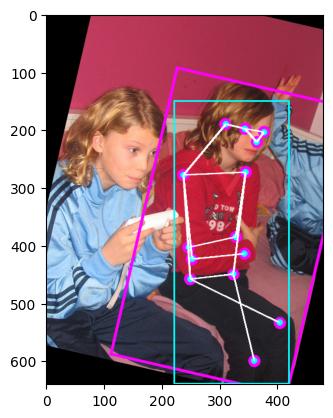

In [268]:
test()